# 01. 분자 그래프(Molecular Graph) 만들기

**SMILES** 문자열로 입력한 분자를 **RDKit** 으로 읽어서
GNN의 입력이 되는 **특성 행렬(Feature Matrix, X)** 과 **인접 행렬(Adjacency Matrix, A)** 을 직접 만들어 봄.

## 분자 = 그래프

| 그래프 | 분자 | 행렬 |
|------|------|------|
| 노드(Node) | 원자(Atom) | 특성 행렬 X : (원자 수 × 특성 수) |
| 엣지(Edge) | 결합(Bond) | 인접 행렬 A : (원자 수 × 원자 수) |

**실습 순서**
```
SMILES 입력  →  RDKit 분자 객체(Mol)  →  원자/결합 정보 추출  →  X, A 행렬  →  시각화
```

- RDKit 공식 문서: https://www.rdkit.org/docs/

## 0. 환경 설정

Google Colab에는 **RDKit이 기본 설치되어 있지 않음** → `pip` 로 먼저 설치함

| 라이브러리 | 용도 |
|------|------|
| `rdkit` | SMILES → 분자 객체 변환, 원자·결합 정보 추출, 분자 그림 |
| `numpy` | 특성 행렬 / 인접 행렬(배열) 만들기 |
| `pandas` | 행렬을 표(DataFrame)로 보기 좋게 출력 |
| `matplotlib` | 행렬과 그래프 시각화 |

In [1]:
# (Colab) RDKit 설치 - 처음 한 번만 실행하면 된다.
!pip install rdkit

from rdkit import Chem                  # SMILES → 분자 객체(Mol)
from rdkit.Chem import Draw             # 분자 구조 그림
from rdkit.Chem import AllChem          # 2D 좌표 계산
import numpy as np                      # 행렬(배열) 처리
import pandas as pd                     # 표(DataFrame) 출력
import matplotlib.pyplot as plt         # 시각화

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 76.5 MB/s  0:00:00


---
## 1. SMILES 입력 → RDKit으로 원자·결합 정보 추출

> **[실습] SMILES로 분자를 입력받아 원자(노드)와 결합(엣지) 정보 확인하기**

- `Chem.MolFromSmiles(SMILES)` : SMILES 문자열을 RDKit **분자 객체(Mol)** 로 변환함
- `mol.GetAtoms()` : 분자의 모든 **원자** 를 하나씩 꺼냄 → 그래프의 **노드**
- `mol.GetBonds()` : 분자의 모든 **결합** 을 하나씩 꺼냄 → 그래프의 **엣지**

**원자(Atom)에서 꺼낼 정보**

| 함수 | 의미 | 예시 |
|------|------|------|
| `GetIdx()` | 원자 번호(순서) | 0, 1, 2, ... |
| `GetSymbol()` | 원소 기호 | C, O, N |
| `GetDegree()` | 연결된 이웃 원자 수 | 3 |
| `GetTotalNumHs()` | 붙어 있는 수소 수 | 1 |
| `GetIsAromatic()` | 방향족 고리 여부 | True / False |

**결합(Bond)에서 꺼낼 정보**

| 함수 | 의미 | 예시 |
|------|------|------|
| `GetBeginAtomIdx()` | 결합의 시작 원자 번호 | 0 |
| `GetEndAtomIdx()` | 결합의 끝 원자 번호 | 1 |
| `GetBondType()` | 결합 종류 | SINGLE, DOUBLE, AROMATIC |

> 💡 엔터만 누르면 기본값 **Aspirin** (`CC(=O)Oc1ccccc1C(=O)O`) 을 사용함

SMILES를 입력하세요 (엔터: Aspirin) : 
입력 SMILES : CC(=O)Oc1ccccc1C(=O)O
원자(노드) 수 : 13
결합(엣지) 수 : 13


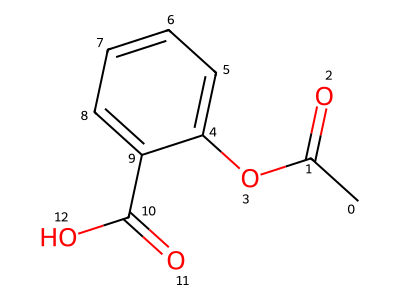

In [2]:
# [1] SMILES 입력받기 (엔터만 누르면 Aspirin 사용)
smiles = input('SMILES를 입력하세요 (엔터: Aspirin) : ')
if smiles == '':
    smiles = 'CC(=O)Oc1ccccc1C(=O)O'

# [2] SMILES → RDKit 분자 객체(Mol)로 변환
mol = Chem.MolFromSmiles(smiles)
print('입력 SMILES :', smiles)
print('원자(노드) 수 :', mol.GetNumAtoms())
print('결합(엣지) 수 :', mol.GetNumBonds())

# [3] 원자 번호를 표시한 분자 구조 그림 (위 표의 idx와 비교해 보기)
for atom in mol.GetAtoms():
    atom.SetProp('atomNote', str(atom.GetIdx()))
Draw.MolToImage(mol, size=(400, 300))

In [7]:
# [4] 원자(Atom) 정보 추출 → 리스트에 dict로 모으기

# *************#
# 실습 코드 작성 #
# *************#

atom_info = []
for atom in mol.GetAtoms():
    atom_info.append({
      'idx' : atom.GetIdx(), # 원자 번호
      'symbol' : atom.GetSymbol(), # 원소 기호
      'degree' : atom.GetDegree(), # 이웃 원자 수
      'num_Hs' : atom.GetTotalNumHs(), # 수소 수
      'aromatic' : atom.GetIsAromatic(), # 방향족 여부
      })

df_atom = pd.DataFrame(atom_info)
display(df_atom)

,idx,symbol,degree,num_Hs,aromatic
0,0,C,1,3,False
1,1,C,3,0,False
2,2,O,1,0,False
3,3,O,2,0,False
4,4,C,3,0,True
5,5,C,2,1,True
6,6,C,2,1,True
7,7,C,2,1,True
8,8,C,2,1,True
9,9,C,3,0,True


In [8]:
# [5] 결합(Bond) 정보 추출 → 리스트에 dict로 모으기

# *************#
# 실습 코드 작성 #
# *************#

bond_info = []
for bond in mol.GetBonds():
    bond_info.append({
      'begin' : bond.GetBeginAtomIdx(), # 시작 원자 번호
      'end' : bond.GetEndAtomIdx(), # 끝 원자 번호
      'type' : str(bond.GetBondType()), # 결합 종류
    })

df_bond = pd.DataFrame(bond_info)
display(df_bond)

,begin,end,type
0,0,1,SINGLE
1,1,2,DOUBLE
2,1,3,SINGLE
3,3,4,SINGLE
4,4,5,AROMATIC
5,5,6,AROMATIC
6,6,7,AROMATIC
7,7,8,AROMATIC
8,8,9,AROMATIC
9,9,10,SINGLE


---
## 2. 특성 행렬(X)과 인접 행렬(A) 만들기

> **[실습] 추출한 원자·결합 정보로 GNN 입력 행렬 만들기**

### 2-1. 특성 행렬 X (Node Feature Matrix)
- 원자 하나 = 행(row) 하나, 원자의 특성 = 열(column)
- 원소 기호는 숫자가 아니므로 **원-핫 인코딩(One-hot)** 으로 바꿈 (해당 원소 자리만 1, 나머지 0)

| 특성 | 차원 | 예시 (방향족 탄소) |
|------|------|------|
| 원소 원-핫 `C, N, O, S, F, Cl, Br, I, 기타` | 9 | `1 0 0 0 0 0 0 0 0` |
| degree (이웃 원자 수) | 1 | `3` |
| num_Hs (수소 수) | 1 | `1` |
| aromatic (방향족 여부) | 1 | `1` |

→ **X 의 크기 = (원자 수 × 12)**

### 2-2. 인접 행렬 A (Adjacency Matrix)
- 원자 i 와 원자 j 가 결합되어 있으면 `A[i, j] = 1`, 아니면 `0`
- 결합에는 방향이 없으므로 `A[i, j]` 와 `A[j, i]` 를 **둘 다** 1로 채움 → **대칭 행렬**

→ **A 의 크기 = (원자 수 × 원자 수)**

In [10]:
# =====================================================================
# [1] 특성 행렬 X 만들기
# =====================================================================

# *************#
# 실습 코드 작성 #
# *************#

atom_list = ['C', 'N', 'O', 'S', 'F', 'Cl', 'Br', 'I', 'Other']
feature_names = atom_list + ['degree', 'num_Hs', 'aromatic']

X = []
for info in atom_info:
    # (a) 원소원-핫인코딩: 전부0으로만든뒤, 해당원소자리만1
    one_hot = [0] * len(atom_list)
    if info['symbol'] in atom_list:
        one_hot[atom_list.index(info['symbol'])] = 1
    else:
        one_hot[-1] = 1                        # 목록에없으면'Other'

    # (b) 나머지특성붙이기(True/False 는int로바꾸면1/0)
    feature = one_hot + [info['degree'], info['num_Hs'], int(info['aromatic'])]
    X.append(feature)

X = np.array(X)
print('특성행렬X 크기:', X.shape, '→ (원자수, 특성수)')

# 표로 보기 (행 이름 = '번호_원소')
atom_labels = [f"{info['idx']}_{info['symbol']}" for info in atom_info]
df_X = pd.DataFrame(X, index=atom_labels, columns=feature_names)
display(df_X)

특성행렬X 크기: (13, 12) → (원자수, 특성수)


,C,N,O,S,F,Cl,Br,I,Other,degree,num_Hs,aromatic
0_C,1,0,0,0,0,0,0,0,0,1,3,0
1_C,1,0,0,0,0,0,0,0,0,3,0,0
2_O,0,0,1,0,0,0,0,0,0,1,0,0
3_O,0,0,1,0,0,0,0,0,0,2,0,0
4_C,1,0,0,0,0,0,0,0,0,3,0,1
5_C,1,0,0,0,0,0,0,0,0,2,1,1
6_C,1,0,0,0,0,0,0,0,0,2,1,1
7_C,1,0,0,0,0,0,0,0,0,2,1,1
8_C,1,0,0,0,0,0,0,0,0,2,1,1
9_C,1,0,0,0,0,0,0,0,0,3,0,1


In [11]:
# =====================================================================
# [2] 인접 행렬 A 만들기
# =====================================================================

# *************#
# 실습 코드 작성 #
# *************#

num_atoms = mol.GetNumAtoms()
A = np.zeros((num_atoms, num_atoms), dtype=int)   # (원자수× 원자수) 0 행렬

for info in bond_info:
    i = info['begin']
    j = info['end']
    A[i, j] = 1                                   # i → j 연결
    A[j, i] = 1                                   # j → i 연결(방향없음→ 대칭)

print('인접행렬A 크기:', A.shape, '→ (원자수, 원자수)')
print('대칭행렬인가? :', (A == A.T).all())

df_A = pd.DataFrame(A, index=atom_labels, columns=atom_labels)
display(df_A)

# (확인) A의 각 행의 합 = 그 원자의 이웃 수 = degree
print('A 행의 합 :', A.sum(axis=1))
print('degree   :', X[:, feature_names.index('degree')])

인접행렬A 크기: (13, 13) → (원자수, 원자수)
대칭행렬인가? : True


,0_C,1_C,2_O,3_O,4_C,5_C,6_C,7_C,8_C,9_C,10_C,11_O,12_O
0_C,0,1,0,0,0,0,0,0,0,0,0,0,0
1_C,1,0,1,1,0,0,0,0,0,0,0,0,0
2_O,0,1,0,0,0,0,0,0,0,0,0,0,0
3_O,0,1,0,0,1,0,0,0,0,0,0,0,0
4_C,0,0,0,1,0,1,0,0,0,1,0,0,0
5_C,0,0,0,0,1,0,1,0,0,0,0,0,0
6_C,0,0,0,0,0,1,0,1,0,0,0,0,0
7_C,0,0,0,0,0,0,1,0,1,0,0,0,0
8_C,0,0,0,0,0,0,0,1,0,1,0,0,0
9_C,0,0,0,0,1,0,0,0,1,0,1,0,0


A 행의 합 : [1 3 1 2 3 2 2 2 2 3 3 1 1]
degree   : [1 3 1 2 3 2 2 2 2 3 3 1 1]


---
## 3. 특성 행렬과 인접 행렬 시각화

> **[실습] 직접 만든 X, A 행렬을 그림으로 확인하기**

| 그림 | 설명 |
|------|------|
| ① 분자 그래프 | **A 행렬만 보고** 원자(노드)를 선으로 연결한 그림 → 실제 분자 구조와 같은지 확인 |
| ② 인접 행렬 A | 결합된 원자 쌍이 진하게 표시됨 (대각선 기준 대칭) |
| ③ 특성 행렬 X | 원자별 특성 값 (원-핫 부분은 행마다 1칸만 진함) |

- 노드의 위치는 RDKit의 `Compute2DCoords` 로 계산한 2D 좌표를 사용함
- 노드 색은 원소 종류(C: 회색, O: 빨강, N: 파랑, 기타: 초록)로 구분함

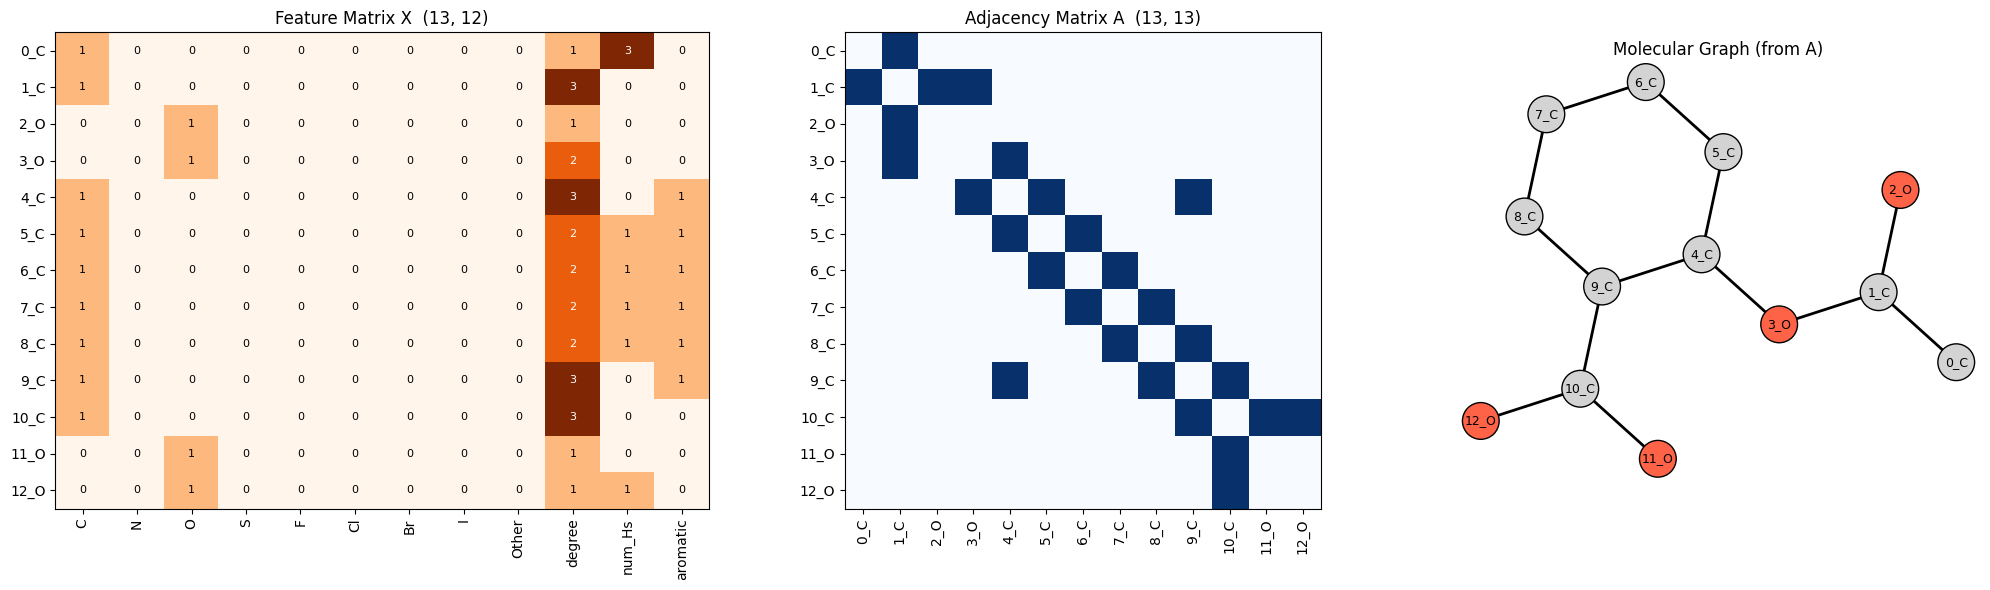

In [12]:
# [0] 노드를 그릴 2D 좌표 계산 (원자마다 x, y 좌표)
AllChem.Compute2DCoords(mol)
pos = mol.GetConformer().GetPositions()[:, :2]     # (원자 수, 2)

# 원소별 노드 색
color_map = {'C': 'lightgray', 'O': 'tomato', 'N': 'cornflowerblue'}
node_colors = [color_map.get(info['symbol'], 'lightgreen') for info in atom_info]

fig, axes = plt.subplots(1, 3, figsize=(20, 6),
                         gridspec_kw={'width_ratios': [1, 1, 0.8]})


# ---------------------------------------------------------------------
# 특성 행렬 X (칸 안에 값 표시)
# ---------------------------------------------------------------------
ax = axes[0]
ax.imshow(X, cmap='Oranges', aspect='auto')
ax.set_xticks(range(len(feature_names)))
ax.set_yticks(range(num_atoms))
ax.set_xticklabels(feature_names, rotation=90)
ax.set_yticklabels(atom_labels)
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        ax.text(j, i, X[i, j], ha='center', va='center', fontsize=8,
                color='white' if X[i, j] >= 2 else 'black')
ax.set_title(f'Feature Matrix X  {X.shape}')

# ---------------------------------------------------------------------
# 인접 행렬 A
# ---------------------------------------------------------------------
ax = axes[1]
ax.imshow(A, cmap='Blues')
ax.set_xticks(range(num_atoms))
ax.set_yticks(range(num_atoms))
ax.set_xticklabels(atom_labels, rotation=90)
ax.set_yticklabels(atom_labels)
ax.set_title(f'Adjacency Matrix A  {A.shape}')

# ---------------------------------------------------------------------
# 분자 그래프 : 인접 행렬 A 에서 1인 칸(i, j)만 선으로 연결
# ---------------------------------------------------------------------
ax = axes[2]
for i in range(num_atoms):
    for j in range(i + 1, num_atoms):              # 대칭이므로 위쪽 절반만 확인
        if A[i, j] == 1:
            ax.plot([pos[i, 0], pos[j, 0]], [pos[i, 1], pos[j, 1]],
                    color='black', linewidth=2, zorder=1)

ax.scatter(pos[:, 0], pos[:, 1], s=700, c=node_colors,
           edgecolors='black', zorder=2)
for i in range(num_atoms):
    ax.text(pos[i, 0], pos[i, 1], atom_labels[i],
            ha='center', va='center', fontsize=9, zorder=3)

ax.set_title('Molecular Graph (from A)')
ax.set_aspect('equal')
ax.axis('off')

plt.tight_layout()
plt.show()
